Import Packages

In [1]:
import pandas as pd

Load the Data

In [2]:
df = pd.read_csv("WAHIS_data.csv")
print(df.head())

   Year      Semester World region  Country Administrative Division  \
0  2005  Jul-Dec 2005       Africa  Algeria                   Alger   
1  2005  Jul-Dec 2005       Africa  Algeria                   Alger   
2  2005  Jul-Dec 2005       Africa  Algeria                 Algeria   
3  2005  Jul-Dec 2005       Africa  Algeria                 Algeria   
4  2005  Jul-Dec 2005       Africa  Algeria                 Algeria   

                                             Disease  \
0  Varroa spp. (Inf. of honey bees with) (Varroosis)   
1  Varroa spp. (Inf. of honey bees with) (Varroosis)   
2                        Bovine tuberculosis (-2018)   
3                        Bovine tuberculosis (-2018)   
4                       Brucella abortus (Inf. with)   

  Serotype/Subtype/Genotype         Animal Category Event_id Species  \
0                       NaN  Both animal categories        -     NaN   
1                       NaN                Domestic        -    Bees   
2                   

/var/folders/8y/fzsxk9yx41b8tt2slg_xz48m0000gn/T/ipykernel_84493/624074253.py:1: DtypeWarning: Columns (0: Event_id, 1: New outbreaks) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("WAHIS_data.csv")


Clean and Filter Data

In [3]:
# Filter for 2005 - 2024
df_filtered = df[df["Year"].between(2005, 2024)].copy()

# Identify orphan rows - species-detail rows without a summary row
group_cols = ["Year", "Semester", "World region", "Country", "Administrative Division", "Disease"]

is_smr = df_filtered["Outbreak_id"] == "-"

has_summary = (
    df_filtered.groupby(group_cols, dropna=False)["Animal Category"]
      .transform(lambda s: (s == "Both animal categories").any())
)
has_summary = has_summary.fillna(False).astype(bool)

orphan_mask = is_smr & ~has_summary
orphan_groups = df_filtered.loc[orphan_mask, group_cols].drop_duplicates()

print(f"{len(orphan_groups):,} orphan groups need a synthetic summary row")

# Build new rows shaped exactly like a real "Both animal categories" summary row
new_rows = orphan_groups.copy()
new_rows["Serotype/Subtype/Genotype"] = ""
new_rows["Animal Category"] = "Both animal categories"
new_rows["Species"] = ""
new_rows["Event_id"] = "-"
new_rows["Outbreak_id"] = "-"
new_rows["New outbreaks"] = 0 # Infer that those without summary row have 0 new outbreaks
new_rows["Susceptible"] = "-"
new_rows["Measuring units"] = "-"
new_rows["Cases"] = "-"
new_rows["Killed and disposed of"] = "-"
new_rows["Slaughtered"] = "-"
new_rows["Deaths"] = "-"
new_rows["Vaccinated"] = "-"

# Flag out synthetic rows so it's clear later which summary rows were real vs. inferred
df_filtered["is_synthetic_summary"] = False
new_rows["is_synthetic_summary"] = True

df_filtered = pd.concat([df_filtered, new_rows], ignore_index=True) # Use df_filtered if want to see species level data

print(f"Added {len(new_rows):,} synthetic summary rows. New total: {len(df_filtered):,}")

df_summary = df_filtered[df_filtered["Animal Category"] == "Both animal categories"] # Use df_summary to only see summary rows

82,775 orphan groups need a synthetic summary row
Added 82,775 synthetic summary rows. New total: 710,495


# Exploratory Data Analysis

**How the data is structured** (worth knowing before aggregating anything):
- **Two reporting channels.** Six-monthly reports (`Outbreak_id == "-"`) and immediate-notification events (`Outbreak_id` filled, ~9k rows). Trends below use the six-monthly reports.
- **Outbreak counts live on summary rows (`Species` is blank).** A summary row is usually `"Both animal categories"`. If a group has no "Both" row, the summary is a `Domestic`/`Wild` row with blank `Species`. **Cases/Deaths/etc.** live on species rows.
- **The synthetic-row step above sets ~52k groups to 0 outbreaks**, even though they have real counts on their Domestic/Wild summary rows (~849k outbreaks). There are also ~107k species rows with no outbreak count at all, and they jump from ~2k/yr to 12–19k/yr from 2020 (WAHIS platform change). Filling those with 0 creates a fake post-2020 drop. The cells below build outbreak counts from the summary rows instead.
- **Some diseases were renamed**, e.g. `Bovine tuberculosis (-2018)` → `Mycobacterium tuberculosis complex (2019-)`. These need merging for time series.
- **Totals are dominated by a few huge reports.** The top 1% of country-disease-years make up ~58% of all outbreaks (e.g. Iran American foulbrood 2011: 918k; Libya Varroa 2016: exactly 200,000). Bee diseases count hives/apiaries, so they're excluded from the cross-disease totals.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Palette (fixed categorical order) and recessive axes
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "lines.linewidth": 2, "axes.prop_cycle": plt.cycler(color=PALETTE),
})

eda = df[df["Year"].between(2005, 2024)].copy()

num_cols = ["New outbreaks", "Susceptible", "Cases", "Killed and disposed of", "Slaughtered", "Deaths", "Vaccinated"]
for c in num_cols:
    eda[c] = pd.to_numeric(eda[c], errors="coerce")  # "-" -> NaN

# Harmonise diseases that were renamed during the period
eda["Disease"] = eda["Disease"].replace({
    "Bovine tuberculosis (-2018)": "Bovine tuberculosis",
    "Mycobacterium tuberculosis complex (Inf. with)(2019-)": "Bovine tuberculosis",
    "High pathogenicity avian influenza viruses (Inf. with) (poultry)": "HPAI (poultry)",
    "Influenza A viruses of high pathogenicity (Inf. with) (non-poultry including wild birds) (2017-)": "HPAI (non-poultry/wild)",
})
BEE_DISEASES = eda.loc[eda["Disease"].str.contains("honey bees|Aethina", regex=True), "Disease"].unique()

smr = eda[eda["Outbreak_id"] == "-"]          # six-monthly reports
species_rows = smr[smr["Species"].notna()]   # cases / deaths / etc.

In [5]:
# Outbreak table: one row per group. Use the "Both" summary row if present, else sum the Domestic/Wild summary rows
summ = smr[smr["Species"].isna()]
both = summ[summ["Animal Category"] == "Both animal categories"][group_cols + ["New outbreaks"]]
by_cat = (summ[summ["Animal Category"] != "Both animal categories"]
          .groupby(group_cols, dropna=False)["New outbreaks"].sum().reset_index())
by_cat = by_cat.merge(both[group_cols].drop_duplicates(), on=group_cols, how="left", indicator=True)
by_cat = by_cat[by_cat["_merge"] == "left_only"].drop(columns="_merge")

outbreaks = pd.concat([both, by_cat], ignore_index=True)
outbreaks["Half"] = np.where(outbreaks["Semester"].str.startswith("Jan"), "Jan-Jun", "Jul-Dec")
print(f"{len(outbreaks):,} groups, {outbreaks['New outbreaks'].sum():,.0f} outbreaks")

# Presence: (Year, Country, Disease) where the disease was reported with >0 outbreaks or >0 cases.
# More robust than outbreak counts across the 2020 reporting change.
presence = pd.concat([
    outbreaks.loc[outbreaks["New outbreaks"] > 0, ["Year", "Country", "Disease"]],
    species_rows.loc[species_rows["Cases"] > 0, ["Year", "Country", "Disease"]],
]).drop_duplicates()

256,712 groups, 5,880,150 outbreaks


## 1. Reporting coverage
Check this first: if fewer countries report, totals fall without any real change in disease. The 2020 dip lines up with COVID and the move to the new WAHIS platform.

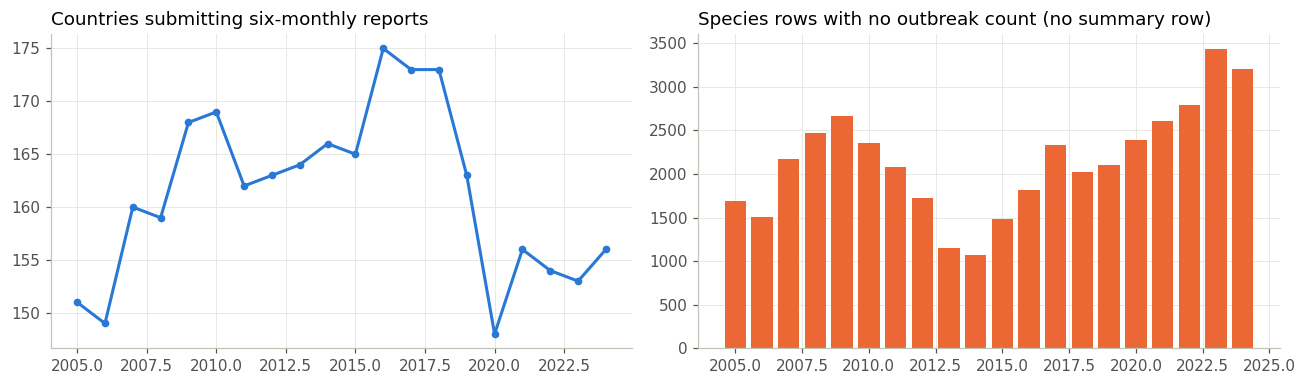

In [6]:
countries_per_year = smr.groupby("Year")["Country"].nunique()
no_count = species_rows[species_rows["New outbreaks"].isna()]
no_count = no_count.merge(summ[group_cols].drop_duplicates(), on=group_cols, how="left", indicator=True)
no_count_per_year = no_count[no_count["_merge"] == "left_only"].groupby("Year").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(countries_per_year.index, countries_per_year.values, marker="o", ms=4)
axes[0].set_title("Countries submitting six-monthly reports", loc="left")
axes[1].bar(no_count_per_year.index, no_count_per_year.values, color=PALETTE[1], width=0.8)
axes[1].set_title("Species rows with no outbreak count (no summary row)", loc="left")
plt.tight_layout(); plt.show()

## 2. Outbreaks over time by region (excluding bee diseases)
Each panel has its own y-scale. Spikes are usually one country and one disease, so check the top-contributors table before reading anything into them.

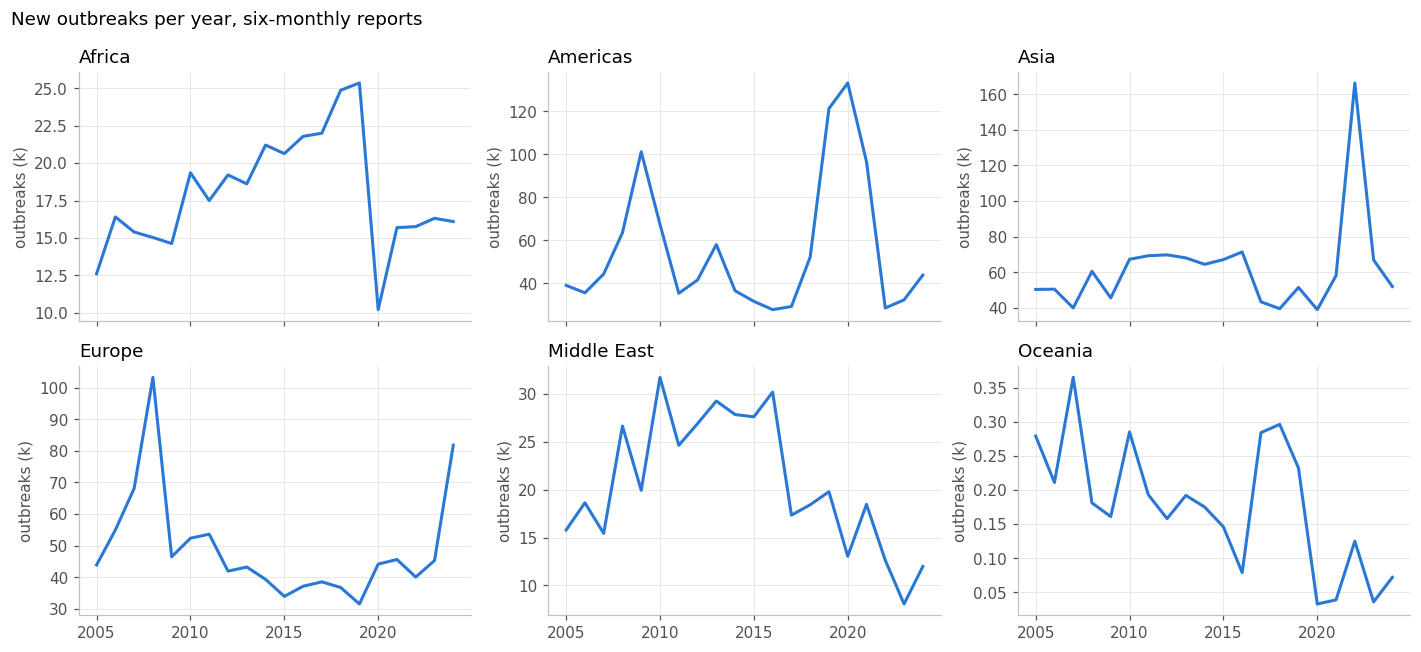

,Year,Country,Disease,New outbreaks
644,2005,Iran,"Theileria annulata, Theileria orientalis and T...",15263.0
664,2005,Ireland,Bovine tuberculosis,6647.0
2174,2006,Iran,"Theileria annulata, Theileria orientalis and T...",13022.0
2194,2006,Ireland,Bovine tuberculosis,6386.0
3464,2007,France,Bluetongue virus (Inf. with),9632.0
3060,2007,Belgium,Bluetongue virus (Inf. with),6837.0
5013,2008,France,Bluetongue virus (Inf. with),27657.0
5663,2008,Peru,Echinococcosis/hydatidosis,20935.0
7303,2009,Peru,Echinococcosis/hydatidosis,66562.0
6801,2009,Iran,Avian infectious bronchitis,8060.0


In [7]:
ob_nb = outbreaks[~outbreaks["Disease"].isin(BEE_DISEASES)]
regions = ["Africa", "Americas", "Asia", "Europe", "Middle East", "Oceania"]
by_region = ob_nb.pivot_table(index="Year", columns="World region", values="New outbreaks", aggfunc="sum").fillna(0)

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, r in zip(axes.flat, regions):
    ax.plot(by_region.index, by_region[r] / 1000, color=PALETTE[0])
    ax.set_title(r, loc="left"); ax.set_ylabel("outbreaks (k)")
fig.suptitle("New outbreaks per year, six-monthly reports", x=0.01, ha="left")
plt.tight_layout(); plt.show()

# What's driving each year's total?
top_drivers = (ob_nb.groupby(["Year", "Country", "Disease"])["New outbreaks"].sum()
               .reset_index().sort_values("New outbreaks", ascending=False)
               .groupby("Year").head(2).sort_values(["Year", "New outbreaks"], ascending=[True, False]))
top_drivers

## 3. Geographic spread of transboundary diseases
Number of countries reporting each disease per year. **African swine fever** grows from ~20 to ~50 countries (Europe 2014+, then China 2018, then SE Asia). **Lumpy skin disease** moves out of Africa through the Middle East (2013–15), the Balkans (2016) and South/East Asia (2019–24). **HPAI** in wild birds jumps from 2021 with the H5N1 panzootic.

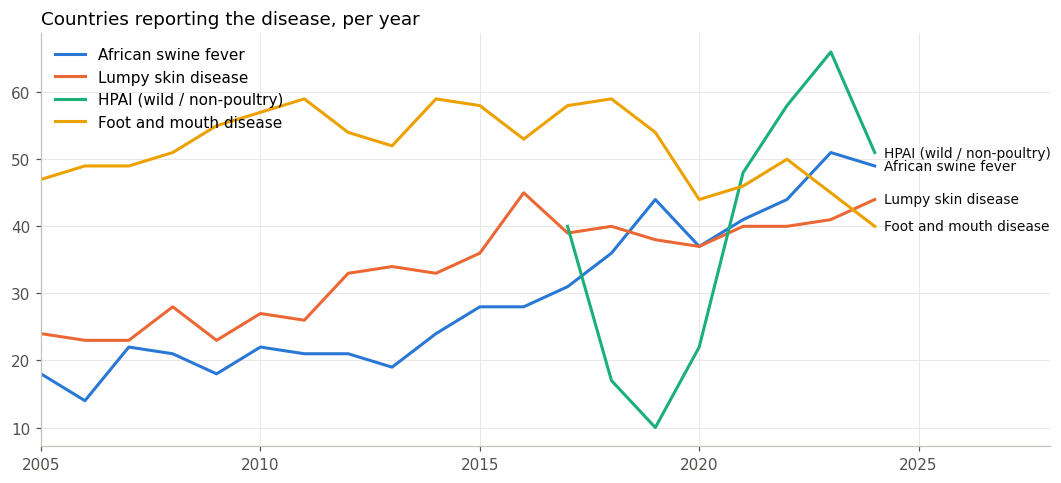


African swine fever - new countries by year
Year
2007    Armenia, Burkina Faso, Congo (Rep. of the), Ge...
2008                                           Azerbaijan
2010                         Central African (Rep.), Chad
2012                                              Ukraine
2013                                              Belarus
2014    Cote D'Ivoire, Estonia, Latvia, Lithuania, Poland
2015                                 Cabo verde, Zimbabwe
2016                                        Mali, Moldova
2017                Czech Republic, Romania, Sierra Leone
2018    Belgium, Bulgaria, China (People's Rep. of), H...
2019    Cambodia, Hong Kong, Indonesia, Korea (Rep. of...
2020                               Germany, Greece, India
2021    Bhutan, Dominican (Rep.), Haiti, Malaysia, Nor...
2022                                         Gabon, Nepal
2023    Bangladesh, Bosnia and Herzegovina, Croatia, S...
2024                                  Albania, Montenegro

Lumpy skin disease - 

In [8]:
spread_dz = {
    "African swine fever virus (Inf. with)": "African swine fever",
    "Lumpy skin disease virus (Inf. with)": "Lumpy skin disease",
    "HPAI (non-poultry/wild)": "HPAI (wild / non-poultry)",
    "Foot and mouth disease virus (Inf. with)": "Foot and mouth disease",
}
spread = (presence[presence["Disease"].isin(spread_dz)]
          .pivot_table(index="Year", columns="Disease", values="Country", aggfunc="nunique")
          .reindex(columns=list(spread_dz)).fillna(0))

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, (dz, label) in enumerate(spread_dz.items()):
    s = spread[dz]
    if dz.startswith("HPAI"):
        s = s[s.index >= 2017]  # category created in 2017
    ax.plot(s.index, s.values, color=PALETTE[i], label=label)
    ax.annotate(label, (s.index[-1], s.values[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color="#0b0b0b", fontsize=9)
ax.set_title("Countries reporting the disease, per year", loc="left")
ax.set_xlim(2005, 2028); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

# First year each country reports the disease (2005-06 used as baseline)
first_seen = presence.groupby(["Disease", "Country"])["Year"].min().reset_index()
new_intros = first_seen[first_seen["Year"] >= 2007]
for dz in ["African swine fever virus (Inf. with)", "Lumpy skin disease virus (Inf. with)"]:
    print(f"\n{spread_dz[dz]} - new countries by year")
    print(new_intros[new_intros["Disease"] == dz].groupby("Year")["Country"].apply(", ".join).to_string())

## 4. HPAI: shift in subtype and in wild-bird involvement
H5N1 dominates until ~2013. H5N8/H5N6 (clade 2.3.4.4) take over from 2014 to 2020. H5N1 returns with a large wave in 2021–23.

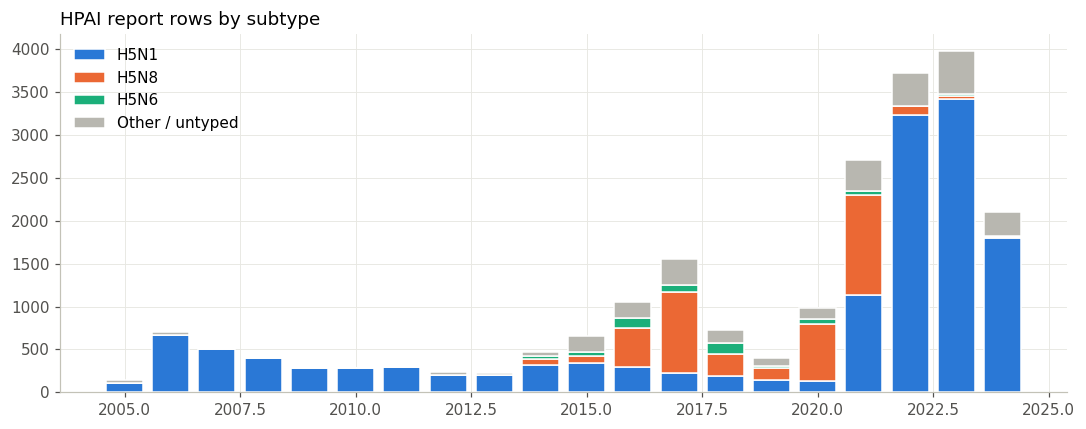

In [9]:
hpai = eda[eda["Disease"].str.startswith("HPAI")]
subtypes = ["H5N1", "H5N8", "H5N6"]
st = pd.crosstab(hpai["Year"], hpai["Serotype/Subtype/Genotype"].where(
    hpai["Serotype/Subtype/Genotype"].isin(subtypes), "Other / untyped"))
st = st[subtypes + ["Other / untyped"]]

fig, ax = plt.subplots(figsize=(10, 4))
bottom = np.zeros(len(st))
colors = PALETTE[:3] + ["#b8b7b0"]
for col, colr in zip(st.columns, colors):
    ax.bar(st.index, st[col], bottom=bottom, color=colr, label=col, width=0.8, edgecolor="white", linewidth=1)
    bottom += st[col].values
ax.set_title("HPAI report rows by subtype", loc="left"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 5. Seasonality: share of outbreaks reported in Jan–Jun
0.5 means no seasonal pattern. Vector-borne diseases (bluetongue, screwworm, lumpy skin) peak in Jul–Dec in the northern-hemisphere summer and autumn. HPAI peaks in Jan–Jun (winter). American foulbrood looks seasonal (0.95), but that comes from one Iran report.

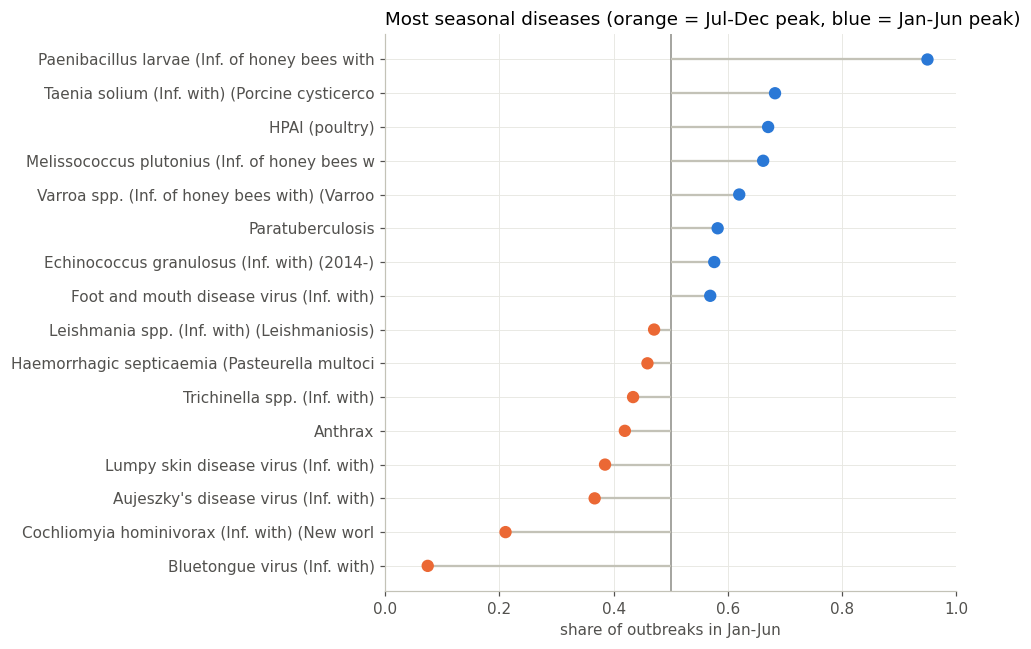

In [10]:
sea = outbreaks.pivot_table(index="Disease", columns="Half", values="New outbreaks", aggfunc="sum").fillna(0)
sea = sea[sea.sum(axis=1) > 20000]
sea["share"] = sea["Jan-Jun"] / sea.sum(axis=1)
sea = sea.sort_values("share")
show = pd.concat([sea.head(8), sea.tail(8)])

fig, ax = plt.subplots(figsize=(9, 6))
ax.axvline(0.5, color="#8c8b85", lw=1)
ax.hlines(range(len(show)), 0.5, show["share"], color="#c3c2b7", lw=1.5)
ax.scatter(show["share"], range(len(show)), s=50, zorder=3,
           color=[PALETTE[1] if v < 0.5 else PALETTE[0] for v in show["share"]])
ax.set_yticks(range(len(show)), [d[:45] for d in show.index])
ax.set_xlim(0, 1); ax.set_xlabel("share of outbreaks in Jan-Jun")
ax.set_title("Most seasonal diseases (orange = Jul-Dec peak, blue = Jan-Jun peak)", loc="left")
plt.tight_layout(); plt.show()

## 6. Severity: case fatality and culling by disease (species rows, animal units only)

In [11]:
sev = species_rows[species_rows["Measuring units"] == "Animal"].groupby("Disease")[
    ["Cases", "Deaths", "Killed and disposed of"]].sum()
sev = sev[sev["Cases"] > 50000]
sev["CFR"] = sev["Deaths"] / sev["Cases"]
sev["culled_per_case"] = sev["Killed and disposed of"] / sev["Cases"]
sev.sort_values("Cases", ascending=False).head(25).round(2)

,Cases,Deaths,Killed and disposed of,CFR,culled_per_case
Disease,,,,,
Infectious hypodermal and haematopoietic necrosis virus (Inf. with),5.097628e+09,53463021.0,5.096851e+09,0.01,1.00
White spot syndrome virus (Inf. with),2.068131e+09,492113707.0,4.174157e+08,0.24,0.20
Avian infectious bronchitis,1.055063e+09,309695856.0,2.641591e+06,0.29,0.00
Newcastle disease virus (Inf. with),7.861850e+08,241284593.0,3.236481e+07,0.31,0.04
Low pathogenic avian influenza (poultry) (2006-2021),4.791404e+08,159896357.0,2.758579e+07,0.33,0.06
Hepatobacter penaei (Inf. with)(Necrotising hepatopancreatitis)(2011-),1.674722e+08,821000.0,2.800000e+02,0.00,0.00
Perkinsus olseni (Inf. with)(2006-),1.618156e+08,145090270.0,5.800000e+01,0.90,0.00
Infectious bursal disease (Gumboro disease),1.595727e+08,51358702.0,8.561770e+05,0.32,0.01
HPAI (poultry),1.011352e+08,48999083.0,6.425111e+08,0.48,6.35
